# Deep Portfolio Constructor, from first principles

**The question:** a long-short equity book should be paid for its *intended* stock views, not for accidental bets on the market, a sector, or a style factor. Can deep learning help build such a book?

This notebook builds the answer up from three ideas, each in a few lines of PyTorch, then shows the real results.

1. **Unintended risk.** Why trading a signal naively hides a factor bet, and how a linear constraint removes it.
2. **The optimiser is a function you can differentiate.** A portfolio optimiser in 15 lines of PyTorch; autograd gives the gradient of the portfolio with respect to its inputs.
3. **Learning through the optimiser.** Train a model on the *portfolio's realised return* instead of on forecast error.
4. **The deep models in this repository.** AlphaFormer (returns), the deep risk model (covariance), and the end-to-end model that trains both through the optimiser.
5. **The real results.** Out-of-sample, walk-forward, net of costs, including what did not work.

Everything in sections 1–3 is simulated and runs in seconds. Sections 4–5 read only committed files, so this runs on a fresh clone with no data download.

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

from dpc.plotting import apply_style, CATEGORICAL, BASELINE, INK_2
%matplotlib inline
apply_style()
torch.manual_seed(0)
rng = np.random.default_rng(0)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)

## 1. Unintended risk: a signal is often a factor in disguise

Simulate 60 stocks. Each return is a **market part** (beta × market move) plus a **stock-specific part**. Our signal has a little genuine skill on the stock-specific part, but it is also correlated with beta: think of a low-volatility signal, which naturally favours low-beta stocks.

Trade it naively (long the high scores, short the low ones, dollar-neutral) and look at where the portfolio's risk comes from.

In [2]:
n, T = 60, 2000
beta = rng.uniform(0.5, 1.5, n)                       # each stock's market beta
market = rng.normal(0, 0.012, T)                      # daily market moves
specific = rng.normal(0, 0.015, (T, n))               # stock-specific moves
returns = np.outer(market, beta) + specific

signal = -(beta - beta.mean()) / beta.std() + 0.3 * rng.normal(size=n)   # mostly "short beta"
w_naive = signal - signal.mean()
w_naive = w_naive / np.abs(w_naive).sum() * 2.0        # 100% long / 100% short

def risk_split(w):
    factor_part = (beta @ w) * market                    # the P&L the market bet explains
    specific_part = specific @ w                         # the P&L the stock picks explain
    v_f, v_s = factor_part.var(), specific_part.var()
    return pd.Series({"portfolio beta": beta @ w, "share of risk from the market bet": v_f / (v_f + v_s)})

risk_split(w_naive)

portfolio beta                      -0.675
share of risk from the market bet    0.755
dtype: float64

The book is dollar-neutral (longs = shorts) but **not market-neutral**: it is short beta, and most of its risk is that one unintended market bet.

The fix is a *linear constraint*. Collect the exposures we refuse to hold as rows of a matrix **A** (here: the dollar row of ones and the beta row) and require **A w = 0**. The closest portfolio to the naive one that satisfies it is a projection:

w_neutral = w − Aᵀ (A Aᵀ)⁻¹ A w

In [3]:
A = np.vstack([np.ones(n), beta])                      # dollar-neutral and beta-neutral
w_neutral = w_naive - A.T @ np.linalg.solve(A @ A.T, A @ w_naive)
w_neutral = w_neutral / np.abs(w_neutral).sum() * 2.0

pd.DataFrame({"naive": risk_split(w_naive), "beta-neutral": risk_split(w_neutral)})

,naive,beta-neutral
portfolio beta,-0.675,4.964e-15
share of risk from the market bet,0.755,1.478e-28


Same signal, same gross exposure, but now almost all of the risk comes from the **stock picks we intended**. That is the whole project in one cell. The real problem has more rows in A (11 sectors, size, value) and inequalities (position caps, turnover), so it needs an optimiser.

## 2. The optimiser is a function you can differentiate

The mean-variance problem with equality constraints,

maximise μᵀw − γ wᵀΣw subject to A w = 0,

has optimality (KKT) conditions that are **linear**:

[2γΣ Aᵀ; A 0] [w; λ] = [μ; 0]

So the optimal portfolio is the solution of a linear system, `torch.linalg.solve` is differentiable, and autograd hands us ∂w*/∂μ. That is the implicit function theorem doing the work. `dpc/deep/torch_qp.py` is that function in 15 lines.

In [4]:
from dpc.deep.torch_qp import neutral_mean_variance

Sigma = torch.tensor(np.cov(returns.T) * 21)             # monthly covariance
A_t = torch.tensor(A)
mu = torch.tensor(0.004 * signal, requires_grad=True)     # expected monthly returns from the signal

w = neutral_mean_variance(mu, Sigma, A_t, gamma=5.0)
print("constraints A w =", (A_t @ w).detach().numpy().round(12), " (exactly neutral)")

# d(expected portfolio return) / d(mu): how each stock's forecast moves the decision's payoff
(mu.detach() @ w).backward()
print("gradient w.r.t. mu, first 5 stocks:", mu.grad[:5].numpy().round(4))

constraints A w = [-0. -0.]  (exactly neutral)
gradient w.r.t. mu, first 5 stocks: [ 0.0286 -0.0013  0.007   0.0538  0.0274]


**Check, don't trust.** The test suite verifies these gradients against finite differences (`torch.autograd.gradcheck`) and against `cvxpy`. The production model uses `cvxpylayers`, which applies the same idea to the full problem with inequalities: position caps, gross leverage, sector bands, factor bands, turnover.

## 3. Learning *through* the optimiser

Usually you fit a forecaster to minimise forecast error, then optimise. But the optimiser does not care about all errors equally. **End-to-end** learning trains the forecaster on what we actually want: the realised return of the portfolio it produces.

Toy version: two signals, only the first has skill. A model learns how much to trust each one, using only realised portfolio returns passed back through the differentiable optimiser.

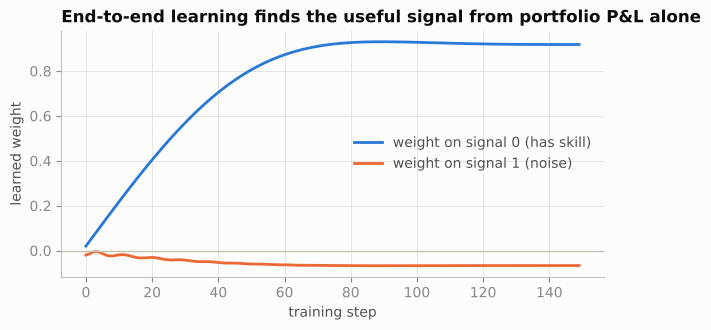

In [5]:
months, n2 = 240, 40
z = torch.randn(months, n2, 2, dtype=torch.float64)                  # two candidate signals per stock
true_mu = 0.01 * z[..., 0]                                            # only signal 0 predicts returns
realised = true_mu + 0.06 * torch.randn(months, n2, dtype=torch.float64)
cov = torch.eye(n2, dtype=torch.float64) * 0.06**2
A2 = torch.ones(1, n2, dtype=torch.float64)                           # dollar-neutral

theta = torch.zeros(2, dtype=torch.float64, requires_grad=True)       # how much to trust each signal
opt = torch.optim.Adam([theta], lr=0.02)
path = []
for step in range(150):
    mu_hat = 0.01 * (z @ theta)                                       # forecast from the signals
    w = neutral_mean_variance(mu_hat, cov.expand(months, -1, -1), A2.expand(months, -1, -1), gamma=5.0)
    pnl = (w * realised).sum(-1)
    loss = -(pnl.mean() - 5.0 * pnl.var())                            # maximise realised mean-variance utility
    opt.zero_grad(); loss.backward(); opt.step()
    path.append(theta.detach().clone().numpy())

path = np.array(path)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(path[:, 0], color=CATEGORICAL[0], label="weight on signal 0 (has skill)")
ax.plot(path[:, 1], color=CATEGORICAL[1], label="weight on signal 1 (noise)")
ax.axhline(0, color=BASELINE, lw=1)
ax.set_xlabel("training step"); ax.set_ylabel("learned weight"); ax.legend(loc="center right")
ax.set_title("End-to-end learning finds the useful signal from portfolio P&L alone")
plt.show()

No one told the model which signal was real. The gradient of the *portfolio's* realised utility, passed back through the optimiser, pushed the weight on the skilled signal up and left the noise near zero.

The same mechanism has a dark side, which section 5 shows on real data: if an unintended bet *paid off* in the training years, end-to-end learning will find it too.

## 4. The deep models in this repository (all PyTorch)

| Layer of the portfolio | Model | What it learns | Loss |
|---|---|---|---|
| **Views:** which stocks beat their peers next month | `AlphaFormer` (`dpc/deep/alpha_model.py`) | attention over each stock's last 12 months, then attention **across stocks** | negative information coefficient (IC) |
| **Risk:** how stocks co-move next month | `DeepRiskModel` (`dpc/deep/risk_model.py`) | patch transformer over 60 days + cross-stock attention, Σ = D(BBᵀ + Ψ)D | Gaussian negative log-likelihood |
| **Decision:** the portfolio | `cvxpylayers` optimiser layer (`dpc/deep/e2e.py`) | gradients of the constrained optimum (KKT) | realised return − costs − λ·variance |

The **fully deep end-to-end model** chains all three, initialises the first two from their walk-forward checkpoints, and fine-tunes everything on the third loss.

In [6]:
from dpc.config import load_config
from dpc.deep.alpha_model import AlphaFormer
from dpc.deep.risk_model import DeepRiskModel, to_return_space

cfg = load_config(ROOT / "config.yaml")
n_sectors, n_stocks = 11, 99
alpha = AlphaFormer(2, 3 + 6 + 3 + n_sectors, cfg.alpha_model).eval()
risk = DeepRiskModel(6, 2 + n_sectors, cfg.risk_model).eval()
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"AlphaFormer: {count(alpha):,} parameters   DeepRiskModel: {count(risk):,} parameters")

# One forward pass on random inputs, to see the shapes and the guarantee
with torch.no_grad():
    mask = torch.ones(1, n_stocks, dtype=torch.bool)
    score, _ = alpha(torch.randn(1, n_stocks, 12, 2), torch.randn(1, n_stocks, 3 + 6 + 3 + n_sectors), mask)
    B, psi, _ = risk(torch.randn(1, 60, n_stocks), torch.randn(1, 60, 6), torch.randn(1, n_stocks, 2 + n_sectors), mask)
    Bh, sh = to_return_space(B.double(), psi.double(), torch.full((1, n_stocks), 0.02, dtype=torch.float64), 21)
    Sigma_hat = Bh[0] @ Bh[0].T + torch.diag(sh[0] ** 2)
print("AlphaFormer scores:", tuple(score.shape), "  covariance:", tuple(Sigma_hat.shape),
      "  smallest eigenvalue:", f"{torch.linalg.eigvalsh(Sigma_hat).min().item():.2e} (> 0 by construction)")

AlphaFormer: 28,033 parameters   DeepRiskModel: 29,033 parameters
AlphaFormer scores: (1, 99)   covariance: (99, 99)   smallest eigenvalue: 8.40e-03 (> 0 by construction)


## 5. The real results

Everything below is **out-of-sample** (models refit once a year on past data only, January 2008 to September 2026), **net of 10 bps costs**, on 99 US and Canadian large caps. The universe is today's large caps, so long-only results carry survivorship bias; the market-neutral comparisons are fairer.

### 5a. Did deep learning find better views?

Rank IC is the correlation between this month's forecast and next month's relative returns. The t-statistic uses Newey-West errors.

In [7]:
ic = pd.read_csv(ROOT / "reports/stage4b_alpha_ic.csv", index_col=0)
ic[["mean_IC", "IC_t_stat_NW", "IC_hit_rate", "n_months"]]

,mean_IC,IC_t_stat_NW,IC_hit_rate,n_months
signal,,,,
momentum,0.016,1.151,0.540,224
reversal,0.002,0.116,0.504,224
low_vol,-0.036,-2.082,0.446,224
combined,-0.004,-0.280,0.522,224
deep_alpha,0.016,1.250,0.540,224


### 5b. The portfolios

In [8]:
perf = pd.read_csv(ROOT / "reports/stage6_performance.csv", index_col=0)
perf[["sharpe", "ann_return", "ann_vol", "max_drawdown", "alpha_ann_ff6", "alpha_t_ff6", "beta_mkt"]]

,sharpe,ann_return,ann_vol,max_drawdown,alpha_ann_ff6,alpha_t_ff6,beta_mkt
Equal weight (LO),0.724,0.128,0.191,-0.485,2.884e-02,3.832,0.918
Min variance (LO),0.599,0.076,0.139,-0.381,-6.200e-03,-0.421,0.695
Mean-variance LW (LO),0.599,0.081,0.149,-0.369,-7.380e-03,-0.578,0.730
Risk parity (LO),0.722,0.115,0.172,-0.450,2.019e-02,2.424,0.849
HRP (LO),0.720,0.109,0.161,-0.413,1.838e-02,2.053,0.788
L/S naive signal,-0.404,-0.087,0.184,-0.877,-7.791e-02,-3.470,-0.163
L/S classical (LW + optimiser),-0.032,-0.006,0.080,-0.319,-1.176e-02,-0.690,0.016
L/S deep risk + optimiser,-0.047,-0.009,0.095,-0.363,-1.977e-02,-1.241,0.053
L/S deep views + deep risk + optimiser,0.333,0.025,0.085,-0.263,1.565e-02,0.802,0.145
L/S end-to-end (classical views),0.582,0.047,0.086,-0.276,3.110e-02,1.475,0.193


### 5c. Where the risk comes from (the headline)

The share of predicted variance that comes from intended stock bets, rather than from style factors or sectors. This is measured with an **independent** Barra-style model (6 style factors + 11 sectors), so no model grades its own homework.

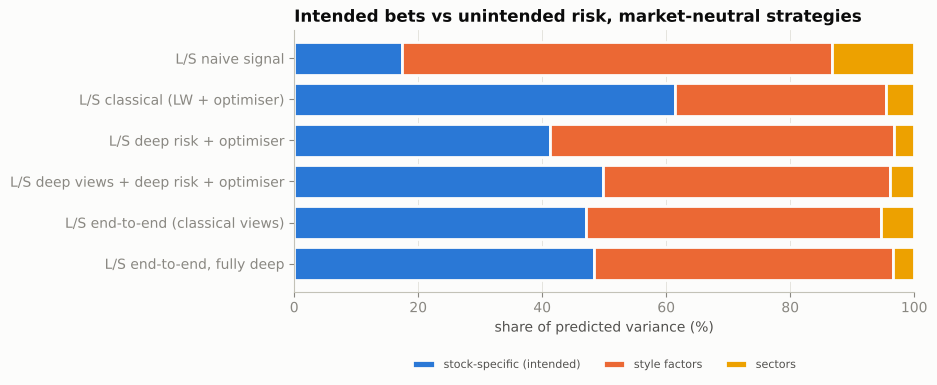

In [9]:
dec = pd.read_csv(ROOT / "reports/stage6_risk_decomposition.csv", index_col=0)
ls = dec[~dec.index.str.contains("LO")]
fig, ax = plt.subplots(figsize=(8, 3.4))
parts = [("exante_share_specific", "stock-specific (intended)", CATEGORICAL[0]),
         ("exante_share_style", "style factors", CATEGORICAL[1]),
         ("exante_share_sector", "sectors", CATEGORICAL[3])]
left = np.zeros(len(ls))
for col, label, color in parts:
    vals = ls[col].clip(lower=0).to_numpy() * 100
    ax.barh(ls.index, vals, left=left, color=color, label=label, edgecolor="#fcfcfb", linewidth=2)
    left += vals
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("share of predicted variance (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=3, fontsize=8)
ax.set_title("Intended bets vs unintended risk, market-neutral strategies")
plt.show()

### 5d. Is it real? Robustness and the leak

Two checks that matter more than the Sharpe ratio: is any edge more than leaked market beta, and is it robust to the random seed?

In [10]:
hedged = pd.read_csv(ROOT / "reports/stage6_beta_hedged.csv", index_col=0)
display(hedged.round(3))
seeds_path = ROOT / "reports/stage6_seeds.csv"
if seeds_path.exists():
    display(pd.read_csv(seeds_path, index_col=0).round(3))

,sharpe_unhedged,sharpe_beta_hedged,avg_trailing_beta,alpha_ff6_hedged,alpha_t_hedged
L/S naive signal,-0.505,-0.287,-0.254,-0.069,-2.578
L/S classical (LW + optimiser),-0.049,0.042,-0.036,-0.004,-0.233
L/S deep risk + optimiser,-0.081,-0.007,-0.026,-0.015,-0.823
L/S deep views + deep risk + optimiser,0.397,0.251,0.114,0.021,1.030
L/S end-to-end (classical views),0.639,0.402,0.177,0.032,1.362
"L/S end-to-end, fully deep",0.218,0.072,0.125,0.007,0.330


,sharpe,ann_return,ann_vol,max_drawdown,alpha_t_ff6,turnover_ann
seed=42,0.582,0.047,0.086,-0.276,1.475,11.140
seed=43,0.457,0.035,0.084,-0.299,0.949,11.232
seed=44,0.495,0.040,0.086,-0.284,1.152,11.519
mean,0.511,0.041,0.085,-0.286,1.192,11.297
std,0.064,0.006,0.001,0.011,0.265,0.198


## What to take away

* **Construction beats prediction for removing unintended risk.** The constrained optimiser, not the neural network, is what turns a factor-driven book into a stock-picking book.
* **Deep learning can improve the decision and still re-introduce unintended risk.** End-to-end training optimises *realised* P&L, so it will exploit any bet that paid in the training years, including estimation error in the constraints themselves.
* **Honest evaluation is the product.** Walk-forward refits, label-date assertions, an independent risk model, seeds, and a cheating-oracle calibration are what make any of these numbers believable.

Read next: `reports/research_note.md` (2 pages) and `reports/stage6_evaluation.md` (every table).